AI Changed the Game. But Who's Really Winning

In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [75]:
import os

file = "survey_results_public.csv"

print("File size (MB):", round(os.path.getsize(file) / (1024**2), 2))

File size (MB): 152.14


In [76]:
with open("survey_results_public.csv", "rb") as f:
    f.seek(-200, 2)
    print(f.read().decode("utf-8", errors="replace"))

Quickly finding code solutions,"Yes, somewhat",NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA



In [77]:
df = pd.read_csv("survey_results_public.csv")
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


In [78]:
df.shape

(65437, 114)

In [79]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Rows: 65437
Columns: 114


In [80]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 65437 entries, 0 to 65436
Columns: 114 entries, ResponseId to JobSat
dtypes: float64(13), int64(1), str(100)
memory usage: 195.6 MB


In [81]:
df.describe()

,ResponseId,CompTotal,WorkExp,JobSatPoints_1,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,ConvertedCompYearly,JobSat
count,65437.000000,3.374000e+04,29658.000000,29324.000000,29393.000000,29411.000000,29450.000000,29448.00000,29456.000000,29456.000000,29450.000000,29445.000000,2.343500e+04,29126.000000
mean,32719.000000,2.963841e+145,11.466957,18.581094,7.522140,10.060857,24.343232,22.96522,20.278165,16.169432,10.955713,9.953948,8.615529e+04,6.935041
std,18890.179119,5.444117e+147,9.168709,25.966221,18.422661,21.833836,27.089360,27.01774,26.108110,24.845032,22.906263,21.775652,1.867570e+05,2.088259
min,1.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,1.000000e+00,0.000000
25%,16360.000000,6.000000e+04,4.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,3.271200e+04,6.000000
50%,32719.000000,1.100000e+05,9.000000,10.000000,0.000000,0.000000,20.000000,15.00000,10.000000,5.000000,0.000000,0.000000,6.500000e+04,7.000000
75%,49078.000000,2.500000e+05,16.000000,22.000000,5.000000,10.000000,30.000000,30.00000,25.000000,20.000000,10.000000,10.000000,1.079715e+05,8.000000
max,65437.000000,1.000000e+150,50.000000,100.000000,100.000000,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000,100.000000,1.625660e+07,10.000000


#Data Quality Check

In [82]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(2)
})

missing.sort_values(
    by="Missing %", ascending=False
).head(20)


,Missing Count,Missing %
AINextMuch less integrated,64289,98.25
AINextLess integrated,63082,96.40
AINextNo change,52939,80.90
AINextMuch more integrated,51999,79.46
EmbeddedAdmired,48704,74.43
EmbeddedWantToWorkWith,47837,73.10
EmbeddedHaveWorkedWith,43223,66.05
ConvertedCompYearly,42002,64.19
AIToolNot interested in Using,41023,62.69
AINextMore integrated,41009,62.67


In [83]:
df.duplicated().sum()

np.int64(0)

In [84]:
selected_columns = [
    "AISelect", "AISent", "DevType", "YearsCodePro",
    "Country", "AIThreat", "ConvertedCompYearly",
    "AIAcc", "AIBen", "AIChallenges"
]

df_project = df[selected_columns].copy()

df_project.shape

(65437, 10)

In [85]:
# Check missing values in selected columns
missing_project = pd.DataFrame({
    "Missing Count": df_project.isnull().sum(),
    "Missing %": (df_project.isnull().mean() * 100).round(2)
})

missing_project.sort_values("Missing %", ascending=False)

,Missing Count,Missing %
ConvertedCompYearly,42002,64.19
AIBen,28543,43.62
AIAcc,28135,43.00
AIChallenges,27906,42.65
AIThreat,20748,31.71
AISent,19564,29.90
YearsCodePro,13827,21.13
Country,6507,9.94
DevType,5992,9.16
AISelect,4530,6.92


In [86]:
# Keep missing values to avoid losing useful data. Handle them separately for each analysis.

In [87]:
# Check for duplicate rows in the selected dataset
df_project.duplicated().sum()

np.int64(9630)

In [88]:
# Keep duplicate-looking rows because the original dataset has no duplicates.

In [89]:
# Check professional experience values
df_project["YearsCodePro"].value_counts(dropna=False)

YearsCodePro
NaN                   13827
2                      4168
3                      4093
5                      3526
10                     3251
4                      3215
Less than 1 year       2856
6                      2843
1                      2639
8                      2549
7                      2517
12                     1777
15                     1635
20                     1549
9                      1493
11                     1312
13                     1127
14                     1082
25                      998
16                      946
18                      867
17                      814
30                      689
24                      632
19                      516
22                      492
23                      448
26                      426
27                      380
21                      380
28                      342
35                      285
29                      196
32                      194
40                      194
34     

In [90]:
# Clean professional experience values
df_project["YearsCodePro_clean"] = pd.to_numeric(
    df_project["YearsCodePro"].replace({
        "Less than 1 year": 0.5,
        "More than 50 years": 51
    }),
    errors="coerce"
)

df_project["YearsCodePro_clean"].describe()

count    51610.000000
mean        10.212013
std          9.079437
min          0.500000
25%          3.000000
50%          7.000000
75%         15.000000
max         51.000000
Name: YearsCodePro_clean, dtype: float64

In [91]:
# Group developers by experience level
df_project["ExperienceLevel"] = pd.cut(
    df_project["YearsCodePro_clean"],
    bins=[0, 3, 10, 20, float("inf")],
    labels=["Beginner", "Intermediate", "Experienced", "Veteran"],
    right=False
)

df_project["ExperienceLevel"].value_counts(dropna=False)

ExperienceLevel
Intermediate    20236
NaN             13827
Experienced     13327
Beginner         9663
Veteran          8384
Name: count, dtype: int64

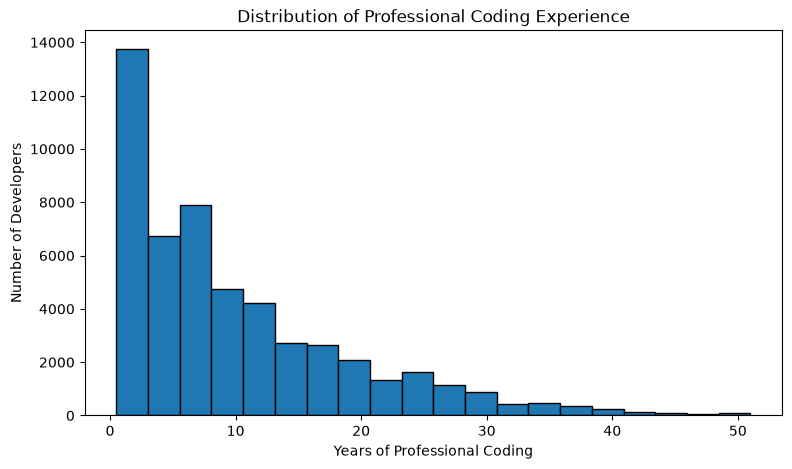

In [92]:
plt.figure(figsize=(9, 5))

plt.hist(df_project["YearsCodePro_clean"].dropna(), bins=20, edgecolor="black")

plt.title("Distribution of Professional Coding Experience")
plt.xlabel("Years of Professional Coding")
plt.ylabel("Number of Developers")
plt.show()

Most developers have relatively few years of professional coding experience. The distribution is right-skewed, with fewer developers reporting longer experience.

In [93]:
# Check annual salary distribution
df_project["ConvertedCompYearly"].describe()

count    2.343500e+04
mean     8.615529e+04
std      1.867570e+05
min      1.000000e+00
25%      3.271200e+04
50%      6.500000e+04
75%      1.079715e+05
max      1.625660e+07
Name: ConvertedCompYearly, dtype: float64

In [94]:
# Detect salary outliers using IQR
Q1 = df_project["ConvertedCompYearly"].quantile(0.25)
Q3 = df_project["ConvertedCompYearly"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Lower bound: -80177.25
Upper bound: 220860.75


In [95]:
# Count salary outliers
salary_outliers = df_project[
    (df_project["ConvertedCompYearly"] < lower_bound) |
    (df_project["ConvertedCompYearly"] > upper_bound)
]

print("Outliers:", len(salary_outliers))

Outliers: 978


In [96]:
# Exclude salary outliers from salary analysis only, while keeping all records in df_project for other analyses.

In [97]:
# Create a salary dataset without outliers
salary_clean = df_project[
    df_project["ConvertedCompYearly"].between(0, upper_bound)
].copy()

salary_clean["ConvertedCompYearly"].describe()

count     22457.000000
mean      71347.201897
std       51271.396445
min           1.000000
25%       32000.000000
50%       63694.000000
75%      101281.000000
max      220207.000000
Name: ConvertedCompYearly, dtype: float64

In [98]:
# Check dataset sizes
print("Project dataset:", df_project.shape)
print("Salary dataset:", salary_clean.shape)

Project dataset: (65437, 12)
Salary dataset: (22457, 12)


#EDA

In [99]:
# Explore AI adoption
df_project["AISelect"].value_counts(dropna=False)

AISelect
Yes                        37662
No, and I don't plan to    14837
No, but I plan to soon      8408
NaN                         4530
Name: count, dtype: int64

In [100]:
# Calculate AI adoption percentages
ai_adoption = (
    df_project["AISelect"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
)

ai_adoption
# Key Finding: About 62% of respondents currently use AI tools.

AISelect
Yes                        61.8
No, and I don't plan to    24.4
No, but I plan to soon     13.8
Name: proportion, dtype: float64

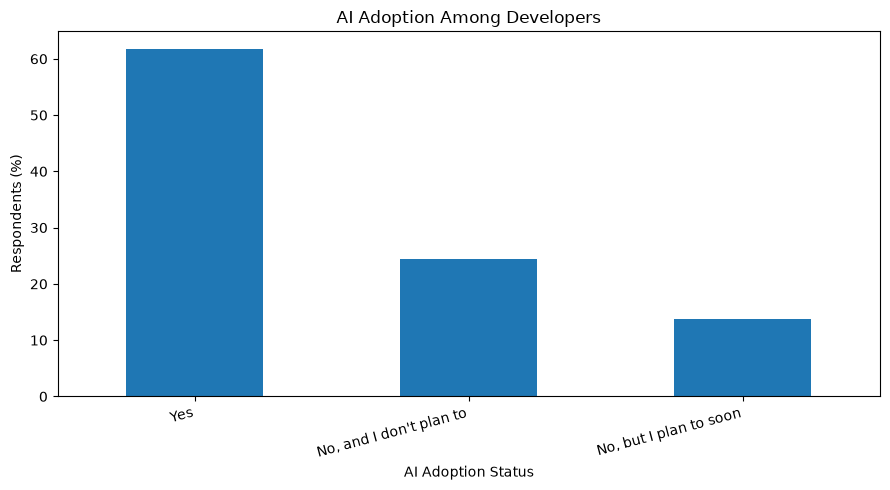

In [101]:
plt.figure(figsize=(9, 5))

ai_adoption.plot(kind="bar")

plt.title("AI Adoption Among Developers")
plt.xlabel("AI Adoption Status")
plt.ylabel("Respondents (%)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [102]:
#Bivariate Analysis
# Compare AI adoption across experience levels
ai_by_experience = pd.crosstab(
    df_project["ExperienceLevel"],
    df_project["AISelect"],
    normalize="index"
).mul(100).round(1)

ai_by_experience

AISelect,"No, and I don't plan to","No, but I plan to soon",Yes
ExperienceLevel,,,
Beginner,19.5,9.3,71.2
Intermediate,21.3,12.6,66.0
Experienced,27.1,15.7,57.2
Veteran,32.6,18.3,49.2


In [103]:
# Key Finding: AI adoption decreases as professional experience increases, from 72.1% among beginners to 49.8% among veterans.

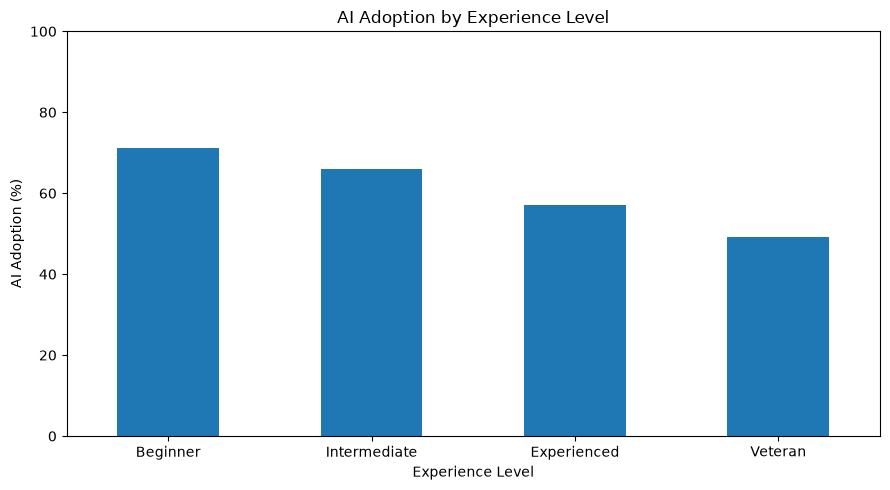

In [104]:
# Visualize AI adoption by experience level
ai_by_experience["Yes"].plot(kind="bar", figsize=(9, 5))

plt.title("AI Adoption by Experience Level")
plt.xlabel("Experience Level")
plt.ylabel("AI Adoption (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [105]:
# Explore the most common developer roles
df_project["DevType"].value_counts().head(10)

DevType
Developer, full-stack                            18260
Developer, back-end                               9928
Student                                           5102
Developer, front-end                              3349
Developer, desktop or enterprise applications     2493
Other (please specify):                           2458
Developer, mobile                                 2021
Developer, embedded applications or devices       1623
Engineering manager                               1275
Academic researcher                               1238
Name: count, dtype: int64

In [106]:
#Bivariate Analysis
# Compare AI adoption across developer roles
top_roles = df_project["DevType"].value_counts().head(10).index

ai_by_role = pd.crosstab(
    df_project["DevType"],
    df_project["AISelect"],
    normalize="index"
).mul(100).round(1)

ai_by_role.loc[top_roles, "Yes"].sort_values(ascending=False)

DevType
Developer, front-end                             69.1
Developer, full-stack                            65.3
Developer, mobile                                65.2
Engineering manager                              62.5
Developer, back-end                              62.0
Student                                          61.5
Academic researcher                              57.8
Other (please specify):                          51.3
Developer, desktop or enterprise applications    45.0
Developer, embedded applications or devices      43.5
Name: Yes, dtype: float64

In [107]:
#AI adoption varies across developer roles. Front-end developers have the highest adoption rate (70.7%), while embedded developers have the lowest (44.5%)

In [108]:
#Bivariate Analysis
# Compare AI adoption with job threat perception
ai_threat = pd.crosstab(
    df_project["AISelect"],
    df_project["AIThreat"],
    normalize="index"
).mul(100).round(1)

ai_threat

AIThreat,I'm not sure,No,Yes
AISelect,,,
"No, but I plan to soon",21.0,67.1,11.9
Yes,19.6,68.3,12.1


In [109]:
#Around 68% of AI users do not perceive AI as a threat to their jobs, while 12% do. Job threat perceptions are similar among current users and those planning to adopt AI.

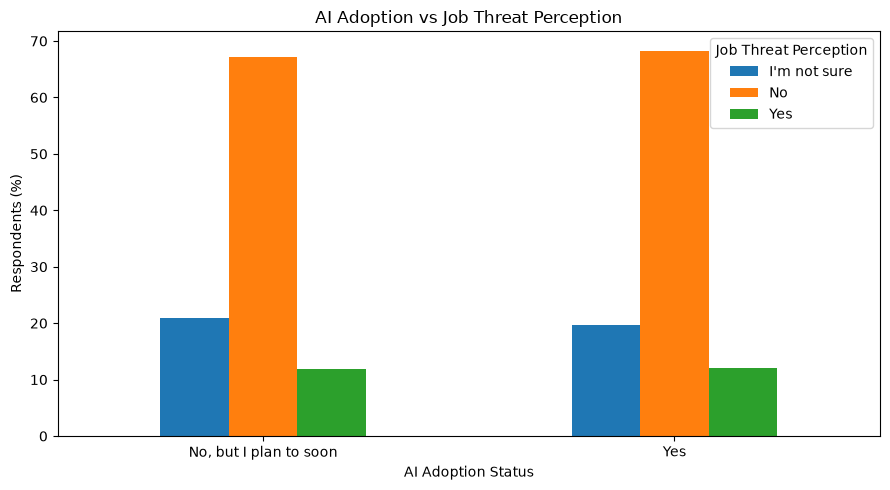

In [110]:
# Visualize AI adoption and job threat perception
ai_threat.plot(kind="bar", figsize=(9, 5))

plt.title("AI Adoption vs Job Threat Perception")
plt.xlabel("AI Adoption Status")
plt.ylabel("Respondents (%)")
plt.xticks(rotation=0)
plt.legend(title="Job Threat Perception")
plt.tight_layout()
plt.show()

In [111]:
# Explore trust in AI accuracy
df_project["AIAcc"].value_counts(dropna=False)

AIAcc
NaN                           28135
Somewhat trust                15039
Neither trust nor distrust     9920
Somewhat distrust              8395
Highly distrust                2932
Highly trust                   1016
Name: count, dtype: int64

In [112]:
# Calculate AI trust percentages
ai_trust = (
    df_project["AIAcc"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
)

ai_trust

AIAcc
Somewhat trust                40.3
Neither trust nor distrust    26.6
Somewhat distrust             22.5
Highly distrust                7.9
Highly trust                   2.7
Name: proportion, dtype: float64

In [113]:
#Only 2.8% of respondents highly trust AI-generated outputs, while 30.9% express some level of distrust.

In [114]:
#Bivariate Analysis
# Compare AI adoption with trust in AI accuracy
ai_adoption_trust = pd.crosstab(
    df_project["AISelect"],
    df_project["AIAcc"],
    normalize="index"
).mul(100).round(1)

ai_adoption_trust

AIAcc,Highly distrust,Highly trust,Neither trust nor distrust,Somewhat distrust,Somewhat trust
AISelect,,,,,
Yes,7.9,2.7,26.6,22.5,40.3


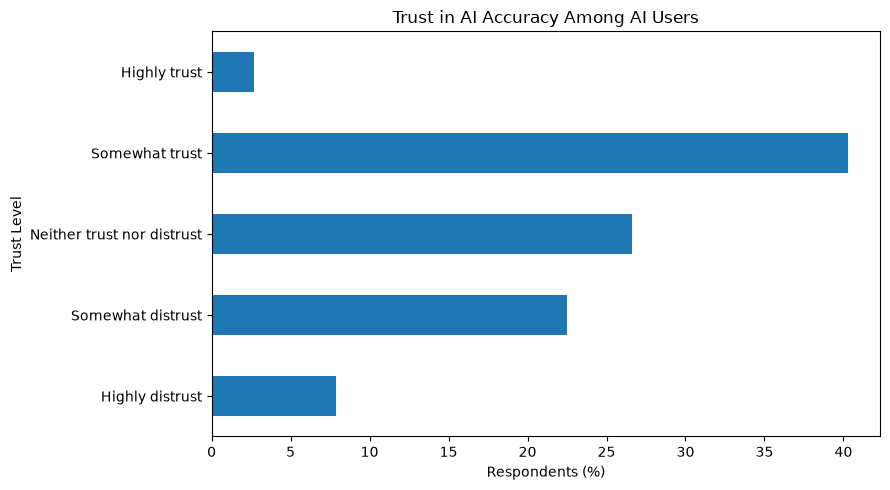

In [115]:
# Visualize trust levels among AI users
trust_order = [
    "Highly distrust",
    "Somewhat distrust",
    "Neither trust nor distrust",
    "Somewhat trust",
    "Highly trust"
]

ai_trust.reindex(trust_order).plot(kind="barh", figsize=(9, 5))

plt.title("Trust in AI Accuracy Among AI Users")
plt.xlabel("Respondents (%)")
plt.ylabel("Trust Level")
plt.tight_layout()
plt.show()

In [116]:
# Compare AI distrust across developer roles
ai_role_trust = pd.crosstab(
    df_project["DevType"],
    df_project["AIAcc"],
    normalize="index"
).mul(100).round(1)

ai_role_trust["Total Distrust"] = (
    ai_role_trust["Highly distrust"] +
    ai_role_trust["Somewhat distrust"]
)

ai_role_trust["Total Distrust"].sort_values(ascending=False)

DevType
Security professional                            50.0
Developer, embedded applications or devices      44.2
Academic researcher                              41.3
Hardware Engineer                                39.5
Developer, game or graphics                      39.4
Engineer, site reliability                       39.1
Cloud infrastructure engineer                    39.0
Developer, desktop or enterprise applications    36.0
Educator                                         35.8
Senior Executive (C-Suite, VP, etc.)             34.3
Research & Development role                      33.7
DevOps specialist                                33.4
Developer Experience                             32.8
Other (please specify):                          32.6
Scientist                                        32.2
Student                                          31.7
Developer, back-end                              31.5
System administrator                             31.2
Engineering manager 

In [117]:
#Security professionals show the highest distrust in AI accuracy (53.5%) among the surveyed job roles

In [118]:
# Check the number of responses by job role
df_project.dropna(subset=["AIAcc"])["DevType"].value_counts().head(40)

DevType
Developer, full-stack                            11621
Developer, back-end                               5990
Student                                           3079
Developer, front-end                              2235
Developer, mobile                                 1275
Other (please specify):                           1234
Developer, desktop or enterprise applications     1098
Engineering manager                                781
Data scientist or machine learning specialist      721
Academic researcher                                691
Developer, embedded applications or devices        690
Data engineer                                      657
DevOps specialist                                  595
Senior Executive (C-Suite, VP, etc.)               577
Research & Development role                        496
Developer, AI                                      434
Cloud infrastructure engineer                      377
Developer, game or graphics                        330
De

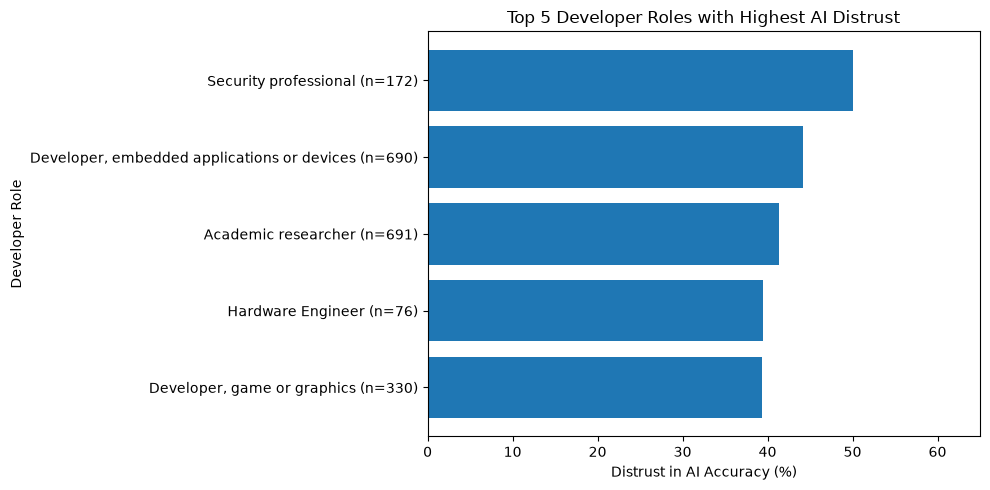

In [119]:
# Visualize the top 5 roles with the highest AI distrust

role_counts = df_project.dropna(subset=["AIAcc"]).groupby("DevType").size()

top5_distrust = (
    ai_role_trust["Total Distrust"]
    .sort_values(ascending=False)
    .head(5)
    .sort_values()
)

labels = [
    f"{role} (n={role_counts[role]})"
    for role in top5_distrust.index
]

plt.figure(figsize=(10, 5))
plt.barh(labels, top5_distrust.values)

plt.title("Top 5 Developer Roles with Highest AI Distrust")
plt.xlabel("Distrust in AI Accuracy (%)")
plt.ylabel("Developer Role")
plt.xlim(0, 65)
plt.tight_layout()
plt.show()

In [120]:
# Explore the reported benefits of AI tools
df_project["AIBen"].value_counts(dropna=False)

AIBen
NaN                                                                                                                          28543
Increase productivity;Greater efficiency;Speed up learning                                                                    4391
Increase productivity;Greater efficiency                                                                                      3901
Increase productivity;Speed up learning                                                                                       3731
Increase productivity                                                                                                         3002
                                                                                                                             ...  
Increase productivity;Greater efficiency;Improve collaboration;Other (please specify):                                           1
Greater efficiency;Improve collaboration;Improve accuracy in coding;Make work

In [121]:
# Count each AI benefit separately
ai_benefits = (
    df_project["AIBen"]
    .dropna()
    .str.split(";")
    .explode()
    .value_counts()
)

ai_benefits

AIBen
Increase productivity            29892
Speed up learning                23022
Greater efficiency               21586
Improve accuracy in coding       11165
Make workload more manageable     9234
Improve collaboration             2867
Other (please specify):           1839
Name: count, dtype: int64

In [122]:
# Calculate AI benefit percentages
total_respondents = df_project["AIBen"].notna().sum()

ai_benefits_pct = (
    ai_benefits / total_respondents * 100
).round(1)

ai_benefits_pct

AIBen
Increase productivity            81.0
Speed up learning                62.4
Greater efficiency               58.5
Improve accuracy in coding       30.3
Make workload more manageable    25.0
Improve collaboration             7.8
Other (please specify):           5.0
Name: count, dtype: float64

Productivity is the most commonly reported AI benefit (81.0%), while 30.3% selected improved coding accuracy. This suggests developers value AI more for productivity than coding accuracy

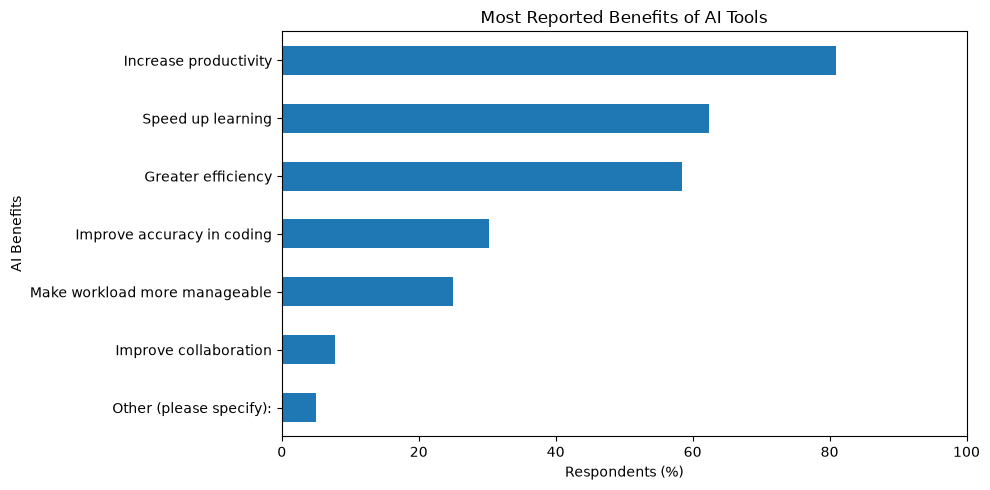

In [123]:
# Visualize AI benefits
ai_benefits_pct.sort_values().plot(
    kind="barh",
    figsize=(10, 5)
)

plt.title("Most Reported Benefits of AI Tools")
plt.xlabel("Respondents (%)")
plt.ylabel("AI Benefits")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

In [124]:
# Explore AI challenges
df_project["AIChallenges"].value_counts(dropna=False)

AIChallenges
NaN                                                                                                                                                                                                                                                                                27906
Don’t trust the output or answers;AI tools lack context of codebase,  internal architecture, and/or company knowledge                                                                                                                                                               5502
Don’t trust the output or answers                                                                                                                                                                                                                                                   3404
AI tools lack context of codebase,  internal architecture, and/or company knowledge                                                             

In [125]:
# Count each AI challenge separately
ai_challenges = (
    df_project["AIChallenges"]
    .dropna()
    .str.split(";")
    .explode()
    .value_counts()
)

ai_challenges

AIChallenges
Don’t trust the output or answers                                                      24450
AI tools lack context of codebase,  internal architecture, and/or company knowledge    23225
We don’t have the right policies in place to reduce security risks                     12192
Lack of proper training and education on new tools                                     11843
Not everyone uses them                                                                  9450
They create more work (more code/PRs to review, etc.)                                   5175
Lack of executive buy-in                                                                4333
Other (please specify):                                                                 2347
Name: count, dtype: int64

In [126]:
# Calculate the percentage of respondents reporting each AI challenge
ai_challenges_pct = (
    ai_challenges
    / df_project["AIChallenges"].notna().sum()
    * 100
).round(1)

ai_challenges_pct

AIChallenges
Don’t trust the output or answers                                                      65.1
AI tools lack context of codebase,  internal architecture, and/or company knowledge    61.9
We don’t have the right policies in place to reduce security risks                     32.5
Lack of proper training and education on new tools                                     31.6
Not everyone uses them                                                                 25.2
They create more work (more code/PRs to review, etc.)                                  13.8
Lack of executive buy-in                                                               11.5
Other (please specify):                                                                 6.3
Name: count, dtype: float64

Lack of trust in AI-generated outputs is the most frequently reported challenge, followed by limited understanding of project context.

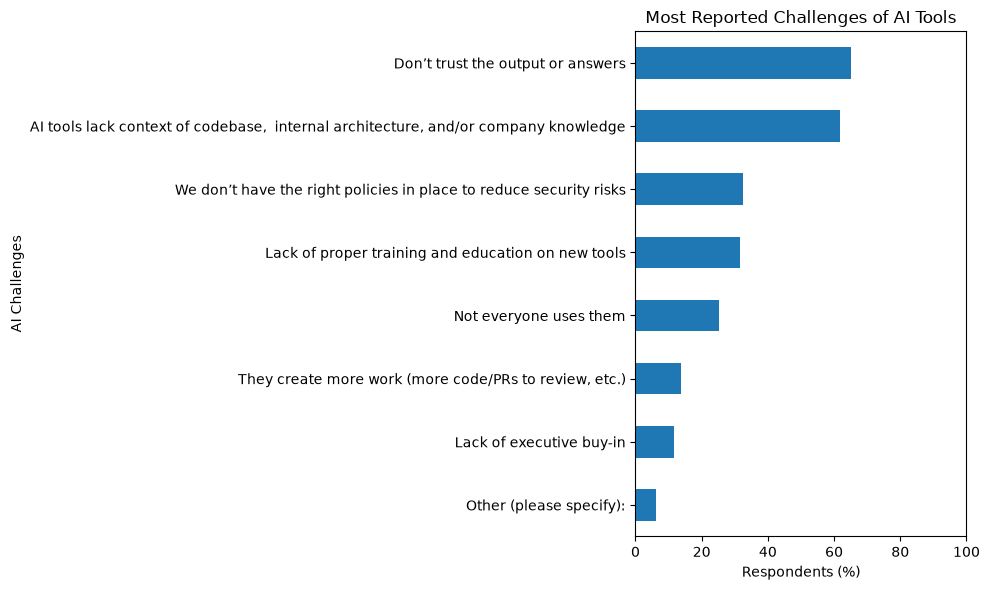

In [127]:
# Visualize the most reported AI challenges

plt.figure(figsize=(10, 6))

ai_challenges_pct.sort_values().plot(kind="barh")

plt.title("Most Reported Challenges of AI Tools")
plt.xlabel("Respondents (%)")
plt.ylabel("AI Challenges")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

In [128]:
# Key Insight: Lack of trust in AI outputs (68.4%) and limited
# understanding of project context (64.8%) are the most
# frequently reported challenges among respondents.

In [129]:
# Bivariate Analysis
# Compare annual salaries across AI adoption groups

ai_salary = (
    salary_clean.groupby("AISelect")["ConvertedCompYearly"]
    .agg(["count", "mean", "median"])
    .round(2)
)

ai_salary

,count,mean,median
AISelect,,,
"No, and I don't plan to",5309,79872.41,72001.0
"No, but I plan to soon",2923,71392.44,63370.0
Yes,14225,68156.16,59073.0


In [130]:
# Identify countries with the most available salary records

salary_clean["Country"].value_counts().head(10)

Country
United States of America                                3990
Germany                                                 2021
Ukraine                                                 1466
United Kingdom of Great Britain and Northern Ireland    1326
India                                                   1030
France                                                   909
Canada                                                   838
Brazil                                                   678
Poland                                                   582
Spain                                                    555
Name: count, dtype: int64

In [131]:
# Compare annual salaries by AI adoption within the USA

usa_salary = salary_clean[
    salary_clean["Country"] == "United States of America"
]

usa_ai_salary = (
    usa_salary.groupby("AISelect")["ConvertedCompYearly"]
    .agg(["count", "median"])
    .round(2)
)

usa_ai_salary

,count,median
AISelect,,
"No, and I don't plan to",1223,128731.0
"No, but I plan to soon",501,131000.0
Yes,2266,130000.0


In the United States, the median annual salary is $130,000 for AI users, $131,000 for those planning to use AI, and $128,731 for those not planning to use AI. These differences do not establish a causal relationship between AI adoption and salary.

In [132]:
# Compare US salaries by AI adoption and experience level

usa_salary_experience = (
    usa_salary.groupby(
        ["ExperienceLevel", "AISelect"],
        observed=True
    )["ConvertedCompYearly"]
    .agg(["count", "median"])
    .round(2)
)

usa_salary_experience

count    median
ExperienceLevel AISelect                                
Beginner        No, and I don't plan to    122   85000.0
                No, but I plan to soon      39   85000.0
                Yes                        342   83545.0
Intermediate    No, and I don't plan to    453  120000.0
                No, but I plan to soon     182  115000.0
                Yes                        926  122000.0
Experienced     No, and I don't plan to    368  140000.0
                No, but I plan to soon     134  146000.0
                Yes                        582  150000.0
Veteran         No, and I don't plan to    278  148800.0
                No, but I plan to soon     145  157000.0
                Yes                        406  160000.0

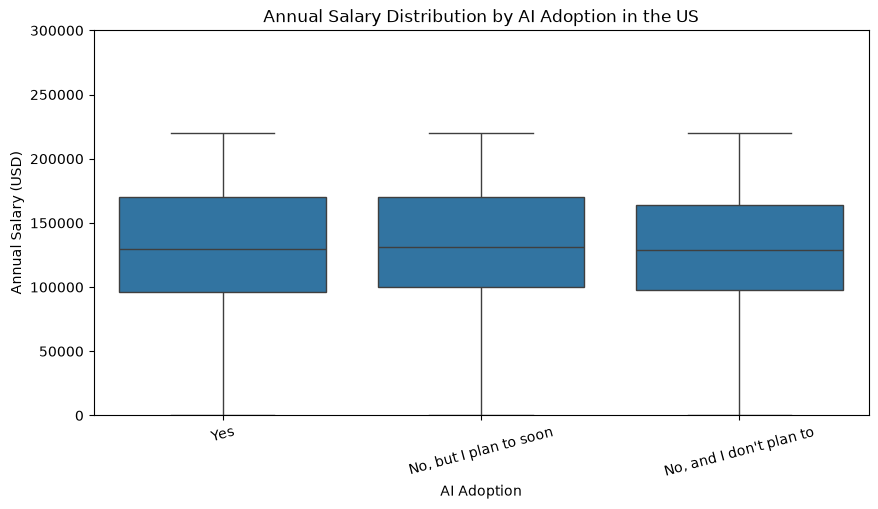

In [133]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=usa_salary,
    x="AISelect",
    y="ConvertedCompYearly"
)

plt.title("Annual Salary Distribution by AI Adoption in the US")
plt.xlabel("AI Adoption")
plt.ylabel("Annual Salary (USD)")
plt.xticks(rotation=15)
plt.ylim(0, 300000)
plt.show()


Salary distributions are similar across AI adoption groups in the US, with median salaries around $130,000. This suggests that AI adoption alone does not explain salary differences.

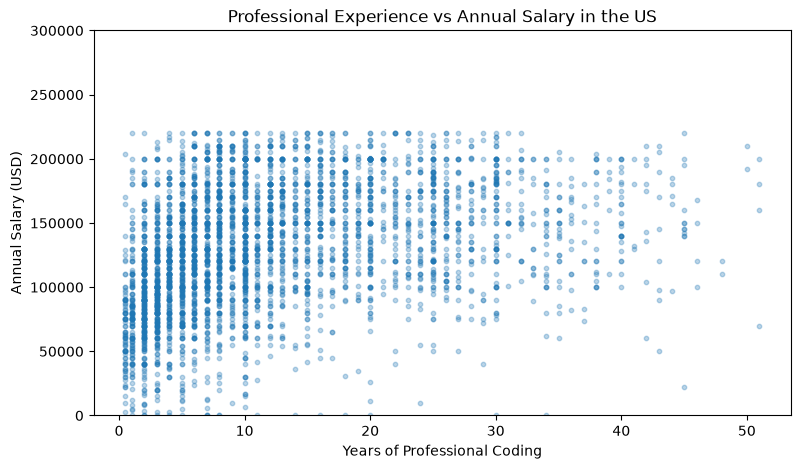

In [134]:
plt.figure(figsize=(9, 5))

plt.scatter(
    usa_salary["YearsCodePro_clean"],
    usa_salary["ConvertedCompYearly"],
    alpha=0.3,
    s=10
)

plt.title("Professional Experience vs Annual Salary in the US")
plt.xlabel("Years of Professional Coding")
plt.ylabel("Annual Salary (USD)")
plt.ylim(0, 300000)
plt.show()

Annual salaries in the US generally tend to increase with professional coding experience. However, salaries vary considerably among developers with similar experience levels.

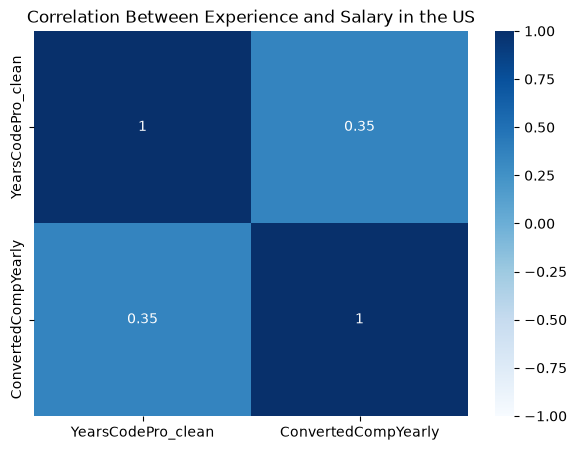

In [135]:
corr_data = usa_salary[
    ["YearsCodePro_clean", "ConvertedCompYearly"]
].dropna()

correlation = corr_data.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="Blues",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Experience and Salary in the US")
plt.show()

There is a moderate positive correlation (r = 0.35) between professional coding experience and annual salary among US developers. This indicates that salaries tend to increase with experience, but experience alone does not fully explain salary differences.

## Multivariate Analysis
### AI Adoption and Salaries by Job Role and Experience in the US

In [136]:
# Compare US salaries by job role, experience, and AI adoption

usa_role_salary = (
    usa_salary.groupby(
        ["DevType", "ExperienceLevel", "AISelect"],
        observed=True
    )["ConvertedCompYearly"]
    .agg(["count", "median"])
    .round(2)
)

usa_role_salary.loc[
    [
        "Developer, full-stack",
        "Developer, back-end",
        "Developer, front-end"
    ]
]

count    median
DevType               ExperienceLevel AISelect                                
Developer, full-stack Beginner        No, and I don't plan to     32   82750.0
                                      No, but I plan to soon      16   83500.0
                                      Yes                        132   80000.0
                      Intermediate    No, and I don't plan to    147  110000.0
                                      No, but I plan to soon      68  105500.0
                                      Yes                        405  120000.0
                      Experienced     No, and I don't plan to    164  140000.0
                                      No, but I plan to soon      53  130000.0
                                      Yes                        257  150000.0
                      Veteran         No, and I don't plan to     99  136000.0
                                      No, but I plan to soon      46  147500.0
                                      Yes                        151  155000.0
Developer, back-end   Beginner        No, and I don't plan to     19   90000.0
                                      No, but I plan to soon       5   60000.0
                                      Yes                         49  105000.0
                      Intermediate    No, and I don't plan to     78  141000.0
                                      No, but I plan to soon      23  160000.0
                                      Yes                        128  140000.0
                      Experienced     No, and I don't plan to     51  173000.0
                                      No, but I plan to soon      17  175000.0
                                      Yes                         96  165000.0
                      Veteran         No, and I don't plan to     49  156000.0
                                      No, but I plan to soon      26  165000.0
                                      Yes                         75  175000.0
Developer, front-end  Beginner        No, and I don't plan to      6   62500.0
                                      No, but I plan to soon       2   90500.0
                                      Yes                         11  104000.0
                      Intermediate    No, and I don't plan to     20  120500.0
                                      No, but I plan to soon      11  110000.0
                                      Yes                         52  127500.0
                      Experienced     No, and I don't plan to     14  133500.0
                                      No, but I plan to soon       2  169500.0
                                      Yes                         24  146000.0
                      Veteran         No, and I don't plan to      7  160000.0
                                      No, but I plan to soon       4  140000.0
                                      Yes                         13  140000.0

AI adoption is not consistently associated with lower salaries. Salary differences vary across experience levels and job roles.

In [137]:
# Keep groups with at least 20 AI users and 20 non-users

salary_comparison = usa_role_salary.unstack("AISelect")

valid_groups = (
    (salary_comparison["count"]["Yes"] >= 20) &
    (salary_comparison["count"]["No, and I don't plan to"] >= 20)
)

salary_comparison[valid_groups]

count  \
AISelect                                                      No, and I don't plan to   
DevType                                       ExperienceLevel                           
Developer, back-end                           Intermediate                       78.0   
                                              Experienced                        51.0   
                                              Veteran                            49.0   
Developer, desktop or enterprise applications Veteran                            28.0   
Developer, embedded applications or devices   Intermediate                       35.0   
Developer, front-end                          Intermediate                       20.0   
Developer, full-stack                         Beginner                           32.0   
                                              Intermediate                      147.0   
                                              Experienced                       164.0   
                                              Veteran                            99.0   

                                                                                      \
AISelect                                                      No, but I plan to soon   
DevType                                       ExperienceLevel                          
Developer, back-end                           Intermediate                      23.0   
                                              Experienced                       17.0   
                                              Veteran                           26.0   
Developer, desktop or enterprise applications Veteran                           11.0   
Developer, embedded applications or devices   Intermediate                      10.0   
Developer, front-end                          Intermediate                      11.0   
Developer, full-stack                         Beginner                          16.0   
                                              Intermediate                      68.0   
                                              Experienced                       53.0   
                                              Veteran                           46.0   

                                                                      \
AISelect                                                         Yes   
DevType                                       ExperienceLevel          
Developer, back-end                           Intermediate     128.0   
                                              Experienced       96.0   
                                              Veteran           75.0   
Developer, desktop or enterprise applications Veteran           29.0   
Developer, embedded applications or devices   Intermediate      22.0   
Developer, front-end                          Intermediate      52.0   
Developer, full-stack                         Beginner         132.0   
                                              Intermediate     405.0   
                                              Experienced      257.0   
                                              Veteran          151.0   

                                                                               median  \
AISelect                                                      No, and I don't plan to   
DevType                                       ExperienceLevel                           
Developer, back-end                           Intermediate                   141000.0   
                                              Experienced                    173000.0   
                                              Veteran                        156000.0   
Developer, desktop or enterprise applications Veteran                        135000.0   
Developer, embedded applications or devices   Intermediate                   120000.0   
Developer, front-end                          Intermediate                   120500.0   
Developer, full-stack                  

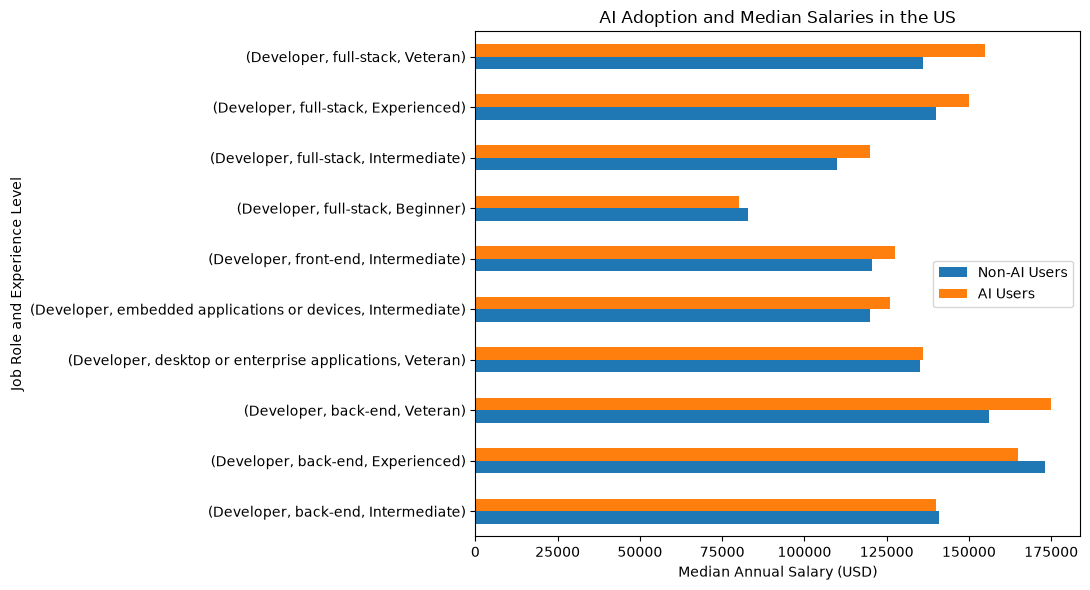

In [138]:
# Compare median salaries between AI users and non-users

salary_plot = salary_comparison.loc[
    valid_groups, "median"
][["No, and I don't plan to", "Yes"]]

salary_plot.plot(kind="barh", figsize=(11, 6))

plt.title("AI Adoption and Median Salaries in the US")
plt.xlabel("Median Annual Salary (USD)")
plt.ylabel("Job Role and Experience Level")
plt.legend(["Non-AI Users", "AI Users"])
plt.tight_layout()
plt.show()

Among ten comparable US developer groups, AI users had higher median salaries in seven groups. However, this does not mean that using AI causes higher salaries

In [139]:
df_project.to_csv("cleaned_data.csv", index=False)